<a href="https://colab.research.google.com/github/edsonportosilva/OpticalCommunications/blob/main/jupyter%20notebooks/English/0.%20Optical%20transmitters.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [34]:
if 'google.colab' in str(get_ipython()):    
    ! git clone -b main https://github.com/edsonportosilva/OptiCommPy
    from os import chdir as cd
    cd('/content/OptiCommPy/')
    ! pip install .
    cd('/content/')
    ! wget https://raw.githubusercontent.com/edsonportosilva/OpticalCommunications/main/jupyter%20notebooks/English/utils.py

# Optical communications

In [35]:
from optic.utils import parameters
import numpy as np
import matplotlib.pyplot as plt

In [36]:
from IPython.display import display, Math
from IPython.display import display as disp

from IPython.core.display import HTML
from IPython.core.pylabtools import figsize

HTML("""
<style>
.output_png {
    display: table-cell;
    text-align: center;
    vertical-align: middle;
}
</style>
""")

In [37]:
figsize(10, 3)

In [38]:
plt.style.use('seaborn-v0_8-darkgrid')

## MZM Parameters

The optical signal at the MZM output is:

\begin{align}
E_{out}(t) &= \frac{E_{in}(t)}{2}e^{j\phi_1(t)} + \frac{E_{in}(t)}{2}e^{j\phi_2(t)} \\
&= E_{in}(t)\cos\left( \frac{u(t)}{2V_{\pi}}\pi \right)
\end{align}

Transmittance, obtained from the relationship of electric field intensities, is:

\begin{equation}
\frac{\left| E_{out}(t) \right|^2}{\left| E_{in}(t) \right|^2} = \frac{P_{out}(t)}{P_{in}(t)} = \frac{1}{2} + \frac{1}{2} \cos\left( \frac{u(t)}{V_{\pi}}\pi \right)
\end{equation}

In [ ]:
#hàm Python mô phỏng tỉ lệ truyền suất trường điện của MZM (tương ứng với phương trình (1))
#Kết quả trả về: Giá trị trường điện ngõ ra tương đối (đã chuẩn hóa) nằm trong khoảng từ -1 đến 1.
def MZM(V, Vdc, Vpi):
  return (np.cos(np.pi/2*(V+Vdc)/Vpi))

In [ ]:
Vmax = 2
Vmin = -2
V = np.linspace(Vmin, Vmax, 100) #chia đều đoạn từ -2 đến 2 thành 100 điểm bằng nhau.

In [41]:
Vpi = 1
Vdc = 0

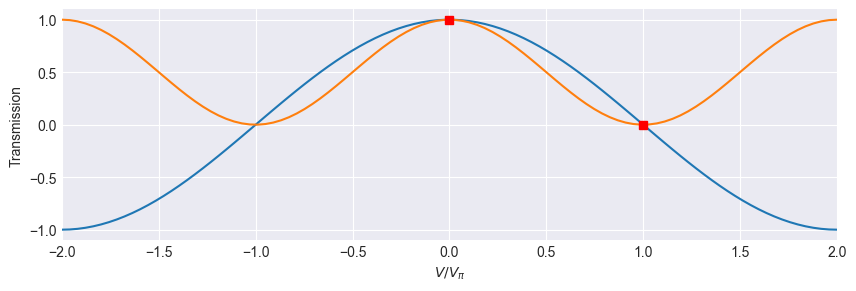

In [ ]:
fig1 = plt.figure() # Khởi tạo một khung hình trống để chuẩn bị vẽ.
plt.plot(V, MZM(V, Vdc, Vpi), label = 'Field') #Vẽ đường Trường điện (Electric Field) ngõ ra (đường màu xanh dương).
plt.plot(V, np.abs(MZM(V, Vdc, Vpi))**2, label = 'Power') #Vẽ đường Công suất quang (Optical Power) ngõ ra (đường màu cam). Công suất bằng bình phương biên độ tuyệt đối của trường điện (P = |E|2)
plt.plot(0, np.abs(MZM(0, Vdc, Vpi))**2, 'sr') #Vẽ một điểm màu đỏ tại vị trí V = 0, biểu diễn công suất ngõ ra tại V = 0.
plt.plot(Vpi, np.abs(MZM(Vpi, Vdc, Vpi))**2, 'sr') #Vẽ một điểm màu đỏ tại vị trí V = Vpi, biểu diễn công suất ngõ ra tại V = Vpi.
plt.xlabel(r'$V/V_\pi$')
plt.ylabel('Transmission')
plt.xlim([Vmin, Vmax])
plt.grid(True)

In [ ]:
Vdc = -Vpi #Việc này làm dịch chuyển toàn bộ đồ thị sang một vị trí mới.

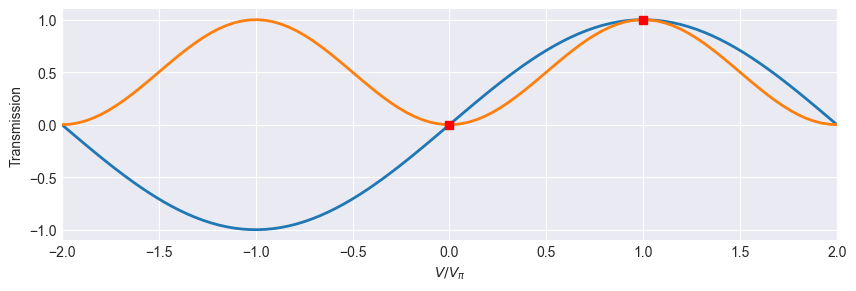

In [44]:
fig2 = plt.figure()
plt.plot(V, MZM(V, Vdc, Vpi), linewidth = 2, label = 'Field')
plt.plot(V, np.abs(MZM(V, Vdc, Vpi))**2, linewidth = 2, label = 'Power')
plt.plot(0, np.abs(MZM(0, Vdc, Vpi))**2, 'sr')
plt.plot(Vpi, np.abs(MZM(Vpi, Vdc, Vpi))**2, 'sr')
plt.xlabel(r'$V/V_\pi$')
plt.ylabel('Transmission')
plt.xlim([Vmin, Vmax])
plt.grid(True)

## Modulating signal

In [ ]:
%pip install OptiCommPy 
#đảm bảo tất cả các hàm toán học chuyên ngành viễn thông quang được nạp đầy đủ vào bộ nhớ để chuẩn bị gọi ra ở các bước tiếp theo.

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.0.1 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [46]:
from commpy.utilities  import signal_power, upsample
from optic.dsp.core import firFilter, pulseShape
from optic.plot import eyediagram

In [47]:
# simulation parameters
SpS = 32

Rs  = 10e9          # Symbol rate (for the case of OOK Rs = Rb)
Ts  = 1/Rs          # Symbol period in seconds
Fa  = 1/(Ts/SpS)    # Signal sampling frequency (samples/second)
Ta  = 1/Fa          # Sampling period
P0  = 1             # Power

In [48]:
# generates sequence of pseudo-random bits
bits   = np.random.randint(2, size=20)    
n      = np.arange(0, bits.size)
# maps bits to OOK symbols
symbTx = np.sqrt(P0)*bits
# upsampling
symbolsUp = upsample(symbTx, SpS)
# ideal rectangular wrist
paramPS = parameters()
paramPS.pulseType = 'rect'
paramPS.SpS = SpS
pulse = pulseShape(paramPS)
pulse = pulse/max(abs(pulse))
# rectangular pulse formatting
sigTx  = firFilter(pulse, symbolsUp)
# signal plot
t = np.arange(0, sigTx.size)*(Ta/1e-12)
# central instants of signaling intervals
symbolsUp = upsample(2*bits-1, SpS)
symbolsUp[symbolsUp==0] = np.nan
symbolsUp = (symbolsUp + 1)/2

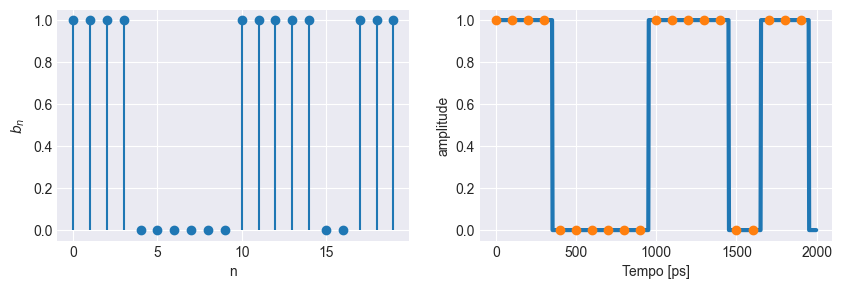

In [49]:
fig, axs = plt.subplots(1, 2)
axs[0].stem(symbTx, basefmt=" ")  # <-- Đã xóa use_line_collection=True ở đây
axs[0].set_xlabel('n')
axs[0].set_ylabel('$b_n$')
axs[0].grid(True)

axs[1].plot(t, sigTx.real, '-', linewidth=3)
axs[1].plot(t, symbolsUp.real, 'o')
axs[1].set_xlabel('Tempo [ps]')
axs[1].set_ylabel('amplitude')
axs[1].grid(True)

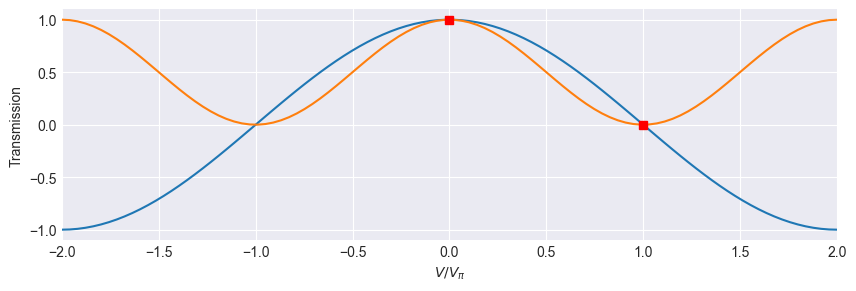

In [50]:
fig1

In [51]:
Vpi  = 1
Vdc  = 0

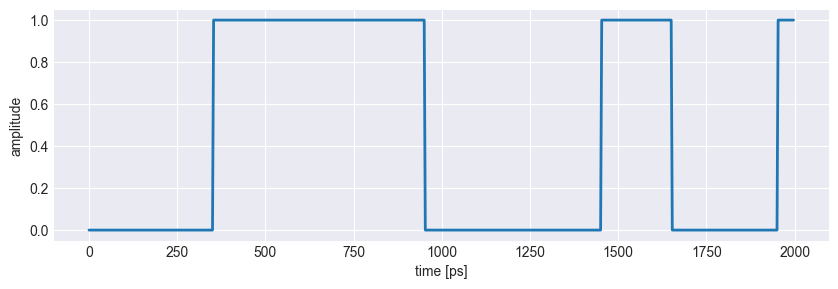

In [52]:
plt.figure()
plt.plot(t, np.abs(MZM(sigTx.real, Vdc, Vpi))**2, linewidth = 2, label = 'Power')
plt.xlabel('time [ps]')
plt.ylabel('amplitude')
plt.grid(True)

In [53]:
Vpi  = 1
Vdc  = -Vpi

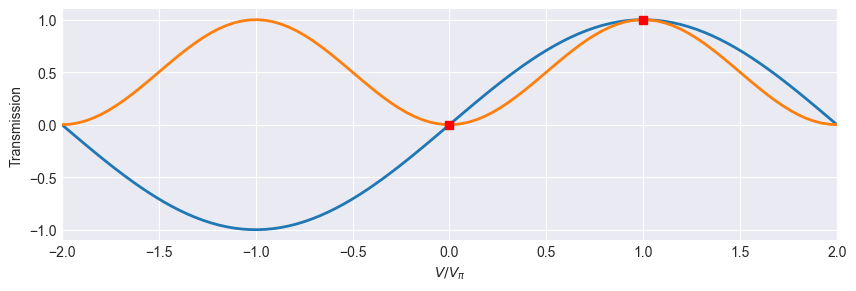

In [54]:
fig2

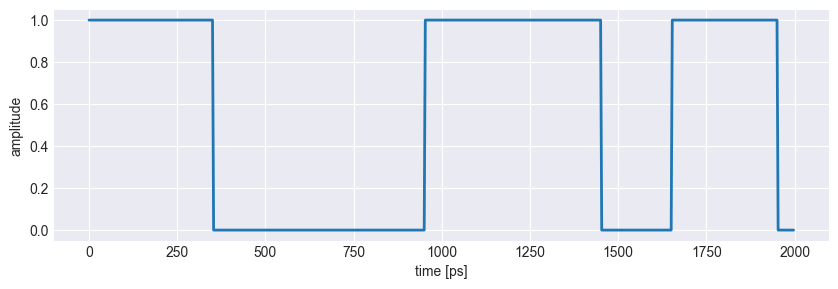

In [55]:
plt.figure()
plt.plot(t, np.abs(MZM(sigTx.real, Vdc, Vpi))**2, linewidth = 2, label = 'Power')
plt.xlabel('time [ps]')
plt.ylabel('amplitude')
plt.grid(True)

In [56]:
Vpi  = 1
Vdc  = -Vpi/2

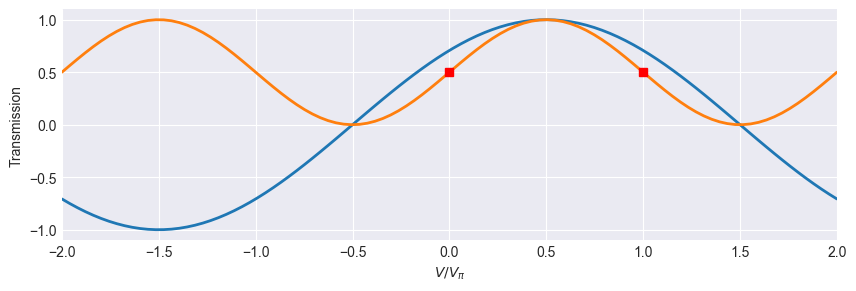

In [57]:
fig3 = plt.figure()
plt.plot(V, MZM(V, Vdc, Vpi), linewidth = 2, label = 'Field')
plt.plot(V, np.abs(MZM(V, Vdc, Vpi))**2, linewidth = 2, label = 'Power')
plt.plot(0, np.abs(MZM(0, Vdc, Vpi))**2, 'sr')
plt.plot(Vpi, np.abs(MZM(Vpi, Vdc, Vpi))**2, 'sr')
plt.xlabel(r'$V/V_\pi$')
plt.ylabel('Transmission')
plt.xlim([Vmin, Vmax])
plt.grid(True)

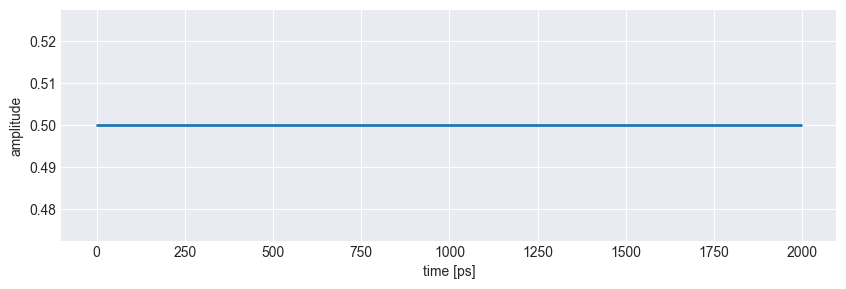

In [58]:
plt.figure()
plt.plot(t, np.abs(MZM(sigTx.real, Vdc, Vpi))**2, linewidth = 2, label = 'Power')
plt.xlabel('time [ps]')
plt.ylabel('amplitude')
plt.grid(True)

## Frequency limitation

Consider that the response of the driver or frequency modulation is limited.

In [59]:
# upsampling
symbolsUp = upsample(symbTx, SpS)
# ideal rectangular wrist
paramPS = parameters()
paramPS.pulseType = 'nrz'
paramPS.SpS = SpS
pulse = pulseShape(paramPS)
pulse = pulse/max(abs(pulse))
# rectangular pulse formatting
sigTx_nrz  = firFilter(pulse, symbolsUp)
# central instants of signaling intervals
symbolsUp = upsample(2*bits-1, SpS)
symbolsUp[symbolsUp==0] = np.nan
symbolsUp = (symbolsUp + 1)/2

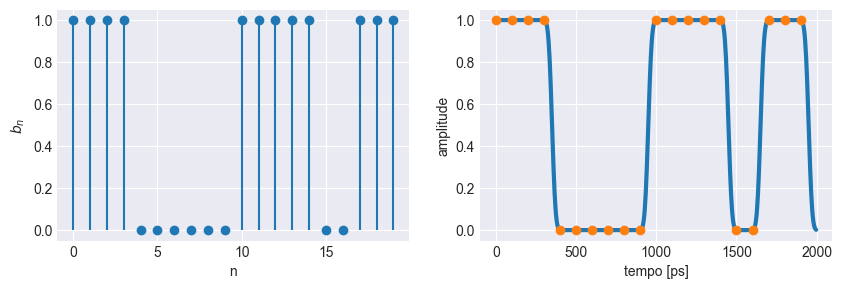

In [60]:
fig, axs = plt.subplots(1, 2)
axs[0].stem(symbTx, basefmt=" ")  # <-- Đã xóa hoàn toàn use_line_collection=True ở đây
axs[0].set_xlabel('n')
axs[0].set_ylabel('$b_n$')
axs[0].grid(True)

axs[1].plot(t, sigTx_nrz.real, '-', linewidth=3)
axs[1].plot(t, symbolsUp.real, 'o')
axs[1].set_xlabel('tempo [ps]')
axs[1].set_ylabel('amplitude')
axs[1].grid(True)

In [61]:
Vpi  = 1
Vdc  = -Vpi

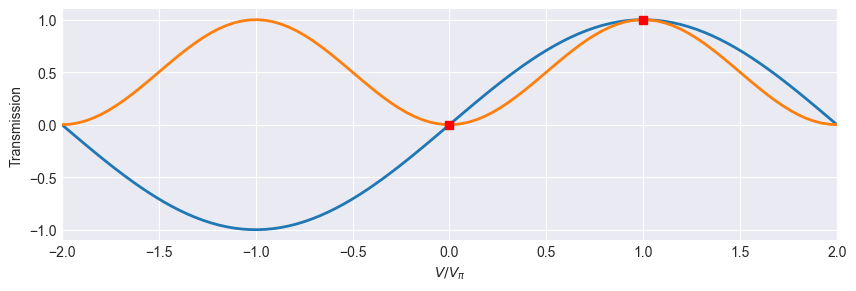

In [62]:
fig2

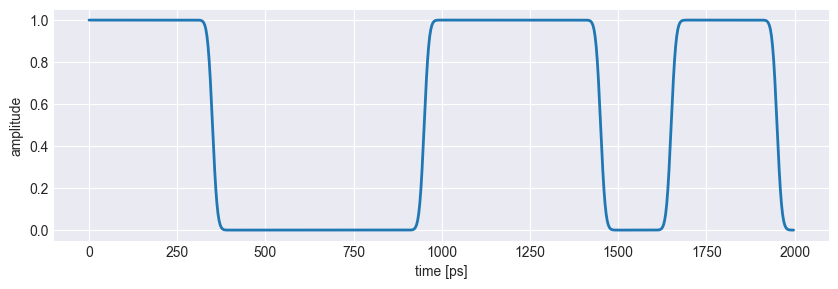

In [63]:
plt.figure()
plt.plot(t, np.abs(MZM(sigTx_nrz.real, Vdc, Vpi))**2, linewidth = 2, label = 'Power')
plt.xlabel('time [ps]')
plt.ylabel('amplitude')
plt.grid(True)

In [64]:
Vpi  = 1
Vdc  = -Vpi/2

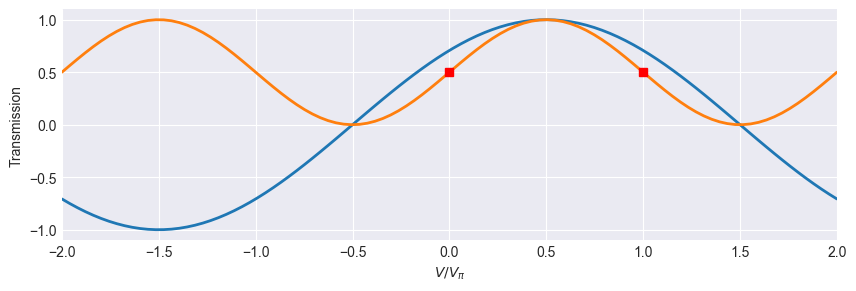

In [65]:
fig3

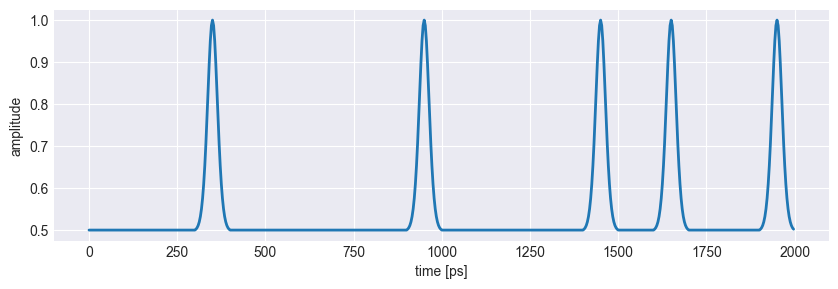

In [66]:
plt.figure()
plt.plot(t, np.abs(MZM(sigTx_nrz.real, Vdc, Vpi))**2, linewidth = 2, label = 'Power')
plt.xlabel('time [ps]')
plt.ylabel('amplitude')
plt.grid(True)